# Feature extraction

Each 5.1-second window holds 255 readings of six channels (accelerometer x, y, z and
gyroscope x, y, z). The HMM reads a short feature vector per window instead, so this
notebook turns every window into six numbers per sensor: three time-domain and three
frequency-domain features. All of them combine the three axes of a sensor, so they do not
depend on how the phone happened to be oriented in the hand.

| Feature | Domain | What it captures |
|---|---|---|
| Standard deviation | time | how strongly the signal swings around its average |
| Axis correlation | time | whether the axes rise and fall together |
| Jerk ratio | time | how sharp the changes are compared with the size of the signal |
| Dominant frequency | frequency | how fast the movement repeats |
| Low-frequency share | frequency | the fraction of the movement's energy below 3 Hz |
| Spectral centroid | frequency | the centre of mass of the frequencies: low for slow movement, high for fast or noisy |

RMS, signal magnitude area and spectral energy were also computed and then removed. The last
section shows why: they repeat the standard deviation almost exactly.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

PROCESSED_DIR = Path("../data/processed")
FEATURES_DIR = Path("../data/features")
FIGURES_DIR = Path("../figures")
ACTIVITIES = ["standing", "walking", "jumping", "still"]
SENSORS = ["acc", "gyro"]
AXES = ["x", "y", "z"]
LOW_FREQUENCY_CUTOFF_HZ = 3.0

FEATURE_NAMES = ["std", "corr", "jerk_ratio", "dom_freq", "low_freq_share", "spec_centroid"]
FEATURE_COLUMNS = [f"{sensor}_{name}" for sensor in SENSORS for name in FEATURE_NAMES]

## Feature functions

Every function takes an array of shape (readings, 3) holding the x, y and z readings of one
sensor in one window. The frequency features work on the magnitude of the signal with its
average removed, and ignore the zero-frequency component of the FFT.

In [2]:
def magnitude(signal):
    """Combined strength of the three axes at each reading."""
    return np.sqrt((signal ** 2).sum(axis=1))


def total_std(signal):
    """Standard deviation over all three axes: square root of the summed variances."""
    return float(np.sqrt(signal.var(axis=0).sum()))


def mean_abs_correlation(signal):
    """Average absolute correlation over the three axis pairs.

    The correlation of a perfectly flat axis is undefined; it is counted as 0.
    """
    values = []
    for first, second in [(0, 1), (0, 2), (1, 2)]:
        if signal[:, first].std() == 0 or signal[:, second].std() == 0:
            values.append(0.0)
        else:
            values.append(abs(np.corrcoef(signal[:, first], signal[:, second])[0, 1]))
    return float(np.mean(values))


def jerk_ratio(signal):
    """Standard deviation of the reading-to-reading change of the magnitude, divided by
    the standard deviation of the magnitude. Small for smooth signals, large for jagged ones."""
    strength = magnitude(signal)
    spread = strength.std()
    return float(np.diff(strength).std() / spread) if spread > 0 else 0.0


def _power_spectrum(signal, sampling_rate_hz):
    """Frequencies in Hz and FFT power of the mean-removed magnitude, zero-frequency bin excluded."""
    strength = magnitude(signal)
    power = np.abs(np.fft.rfft(strength - strength.mean())) ** 2
    frequencies = np.fft.rfftfreq(len(strength), d=1 / sampling_rate_hz)
    return frequencies[1:], power[1:]


def dominant_frequency(signal, sampling_rate_hz):
    """Frequency in Hz of the strongest component of the magnitude."""
    frequencies, power = _power_spectrum(signal, sampling_rate_hz)
    return float(frequencies[power.argmax()])


def low_frequency_share(signal, sampling_rate_hz, cutoff_hz=LOW_FREQUENCY_CUTOFF_HZ):
    """Fraction of the spectral power that lies below `cutoff_hz` (0 if there is no power)."""
    frequencies, power = _power_spectrum(signal, sampling_rate_hz)
    total = power.sum()
    return float(power[frequencies < cutoff_hz].sum() / total) if total > 0 else 0.0


def spectral_centroid(signal, sampling_rate_hz):
    """Power-weighted average frequency in Hz (0 if there is no power)."""
    frequencies, power = _power_spectrum(signal, sampling_rate_hz)
    total = power.sum()
    return float((frequencies * power).sum() / total) if total > 0 else 0.0

## Compute the features for every window

The sampling rate is taken from the timestamps of each window, so the frequency features use
the measured interval (about 20.03 ms) and not the nominal 50 Hz.

In [3]:
def window_features(window):
    """Return a dictionary with the 12 feature values of one window."""
    sampling_rate_hz = 1 / window["time_s"].diff().median()
    features = {}
    for sensor in SENSORS:
        signal = window[[f"{sensor}_{axis}" for axis in AXES]].to_numpy()
        features[f"{sensor}_std"] = total_std(signal)
        features[f"{sensor}_corr"] = mean_abs_correlation(signal)
        features[f"{sensor}_jerk_ratio"] = jerk_ratio(signal)
        features[f"{sensor}_dom_freq"] = dominant_frequency(signal, sampling_rate_hz)
        features[f"{sensor}_low_freq_share"] = low_frequency_share(signal, sampling_rate_hz)
        features[f"{sensor}_spec_centroid"] = spectral_centroid(signal, sampling_rate_hz)
    return features


windows = [
    (activity, path.name, pd.read_csv(path))
    for activity in ACTIVITIES
    for path in sorted((PROCESSED_DIR / activity).glob("*.csv"))
]
feature_table = pd.DataFrame(
    [{"file": name, "activity": activity.capitalize(), **window_features(window)}
     for activity, name, window in windows]
)
FEATURES_DIR.mkdir(parents=True, exist_ok=True)
feature_table.to_csv(FEATURES_DIR / "window_features.csv", index=False)
print(feature_table.shape, "feature table saved to", FEATURES_DIR / "window_features.csv")
assert not feature_table[FEATURE_COLUMNS].isna().any().any()

(92, 14) feature table saved to ..\data\features\window_features.csv


## Typical value of each feature per activity (median over the 23 windows)

In [4]:
feature_table.groupby("activity")[FEATURE_COLUMNS].median().loc[
    ["Still", "Standing", "Walking", "Jumping"]
].round(3).T

activity,Still,Standing,Walking,Jumping
acc_std,0.008,0.176,1.237,7.248
acc_corr,0.063,0.339,0.157,0.470
acc_jerk_ratio,1.363,0.709,0.530,0.697
acc_dom_freq,0.979,0.196,1.174,4.698
acc_low_freq_share,0.187,0.488,0.630,0.151
acc_spec_centroid,11.589,4.495,3.228,5.213
gyro_std,0.003,0.061,0.596,1.281
gyro_corr,0.061,0.248,0.406,0.230
gyro_jerk_ratio,1.402,0.547,0.420,0.778
gyro_dom_freq,8.809,0.196,0.587,2.349


## Do the features repeat each other?

Two features that rise and fall together carry almost the same information. Rank
correlation (Spearman) is used because several features are skewed. Pairs with a correlation
of 0.9 or more are listed.

In [5]:
FIGURES_DIR.mkdir(exist_ok=True)

correlations = feature_table[FEATURE_COLUMNS].corr(method="spearman")
pairs = [
    (a, b, correlations.loc[a, b])
    for i, a in enumerate(FEATURE_COLUMNS)
    for b in FEATURE_COLUMNS[i + 1:]
    if abs(correlations.loc[a, b]) >= 0.9
]
pd.DataFrame(pairs, columns=["feature_a", "feature_b", "spearman"]).round(3)

,feature_a,feature_b,spearman
0,acc_std,gyro_std,0.964
1,acc_jerk_ratio,acc_spec_centroid,0.956
2,gyro_jerk_ratio,gyro_low_freq_share,-0.965
3,gyro_jerk_ratio,gyro_spec_centroid,0.994
4,gyro_low_freq_share,gyro_spec_centroid,-0.980


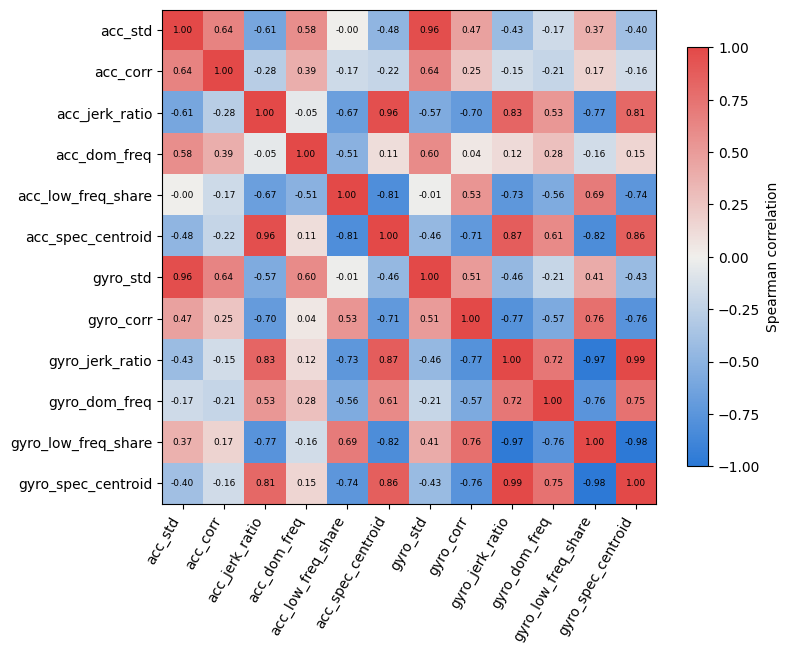

In [6]:
cmap = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(8, 6.8))
image = ax.imshow(correlations, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS, rotation=60, ha="right")
ax.set_yticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS)
for i in range(len(FEATURE_COLUMNS)):
    for j in range(len(FEATURE_COLUMNS)):
        ax.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(image, ax=ax, shrink=0.8, label="Spearman correlation")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_correlation.png", dpi=200, bbox_inches="tight")
plt.show()

## Does each feature separate the activities?

The score is the share of the variation in a feature's ranks that is explained by which
activity the window belongs to (eta squared on ranks): 1 means the four activities never
overlap, 0 means the feature says nothing about the activity.

In [7]:
def separation_scores(table, columns):
    """Eta squared of the ranks of each column, grouped by activity."""
    ranks = table[columns].rank()
    total = ((ranks - ranks.mean()) ** 2).sum()
    group_means = ranks.groupby(table["activity"]).transform("mean")
    between = ((group_means - ranks.mean()) ** 2).sum()
    return between / total


separation_scores(feature_table, FEATURE_COLUMNS).sort_values(ascending=False).round(3).to_frame("separation")

,separation
acc_std,0.938
gyro_std,0.927
gyro_jerk_ratio,0.817
gyro_spec_centroid,0.811
gyro_low_freq_share,0.784
acc_corr,0.777
acc_jerk_ratio,0.763
acc_spec_centroid,0.740
acc_low_freq_share,0.709
gyro_corr,0.631


## What the activities look like in feature space

Each panel highlights one activity (blue) against the other three (gray). The top row uses
accelerometer features and the bottom row gyroscope features. The strength axis uses a
logarithmic scale because the values span several orders of magnitude.

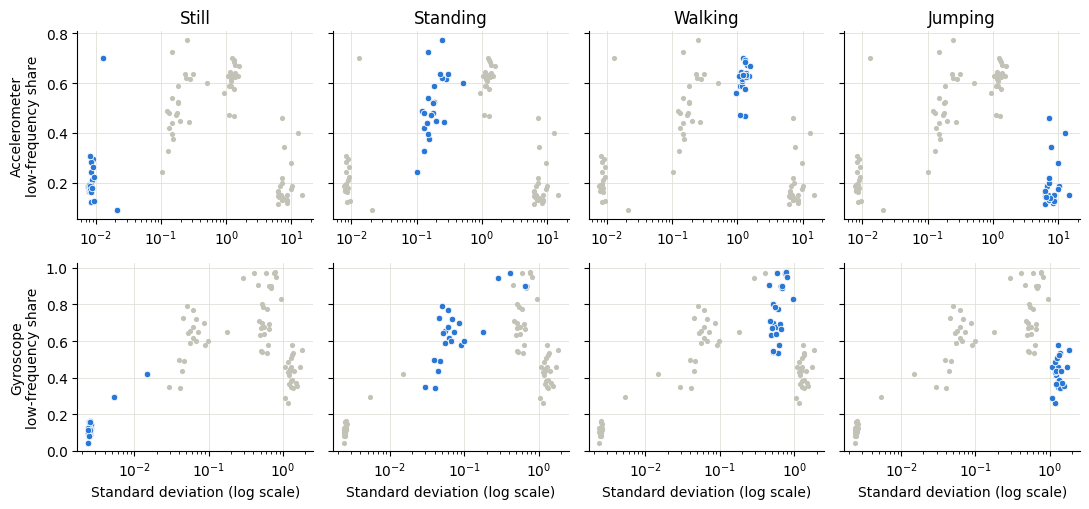

In [8]:
PANEL_ORDER = ["Still", "Standing", "Walking", "Jumping"]
PAIRS = [("acc_std", "acc_low_freq_share", "Accelerometer"), ("gyro_std", "gyro_low_freq_share", "Gyroscope")]

fig, axes = plt.subplots(2, 4, figsize=(11, 5.2), sharex="row", sharey="row")
for row, (strength, rhythm, sensor) in enumerate(PAIRS):
    for col, activity in enumerate(PANEL_ORDER):
        ax = axes[row, col]
        others = feature_table[feature_table["activity"] != activity]
        chosen = feature_table[feature_table["activity"] == activity]
        ax.scatter(others[strength], others[rhythm], s=14, color="#c3c2b7", linewidths=0)
        ax.scatter(chosen[strength], chosen[rhythm], s=22, color="#2a78d6", edgecolors="#fcfcfb", linewidths=0.6)
        ax.set_xscale("log")
        ax.grid(color="#e1e0d9", linewidth=0.6)
        ax.set_axisbelow(True)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        if row == 0:
            ax.set_title(activity)
        if row == 1:
            ax.set_xlabel("Standard deviation (log scale)")
    axes[row, 0].set_ylabel(f"{sensor}\nlow-frequency share")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

## Features that were tried and removed

RMS, signal magnitude area (SMA) and spectral energy were computed for every window as well.
The table shows their rank correlation with the standard deviation of the same sensor.
Values close to 1 mean they add nothing the standard deviation does not already say.

In [9]:
def removed_features(window, sampling_rate_hz):
    """RMS, SMA and spectral energy of the accelerometer and gyroscope signals of one window."""
    values = {}
    for sensor in SENSORS:
        signal = window[[f"{sensor}_{axis}" for axis in AXES]].to_numpy()
        _, power = _power_spectrum(signal, sampling_rate_hz)
        values[f"{sensor}_rms"] = float(np.sqrt((signal ** 2).sum(axis=1).mean()))
        values[f"{sensor}_sma"] = float(np.abs(signal).sum(axis=1).mean())
        values[f"{sensor}_spec_energy"] = float(power.sum() / len(signal))
    return values


removed = pd.DataFrame(
    [removed_features(window, 1 / window["time_s"].diff().median()) for _, _, window in windows]
)
rows = {
    name: {
        sensor: removed[f"{sensor}_{name}"].corr(feature_table[f"{sensor}_std"], method="spearman")
        for sensor in SENSORS
    }
    for name in ["rms", "sma", "spec_energy"]
}
pd.DataFrame(rows).T.round(3).rename(columns={"acc": "acc vs acc_std", "gyro": "gyro vs gyro_std"})

,acc vs acc_std,gyro vs gyro_std
rms,0.985,0.997
sma,0.984,0.993
spec_energy,0.992,0.980
